# 06 · Which factors are worth doing by hand?

The pipeline can guess everything automatically. This notebook checks, **with numbers from the real Canedo recording**,
where a person's input (setup UI) or check (review UI) pays off — and where it does not. Rule used:
*manual when the automatic estimate is unreliable, an error spreads to many statistics or fails silently, and a person
can give it in seconds or minutes.*

| Section | Factor | Question |
|---|---|---|
| 1 | shirt numbers / player identity | can a person (or OCR) label players per tracklet? |
| 2 | team kits | do a few clicked kit samples beat unsupervised colour clustering? |
| 3 | pitch size and positions | how much does a position error move xG? |
| 4 | direction / periods | how fragile is the automatic inference? |
| 5 | calibration and key events | what does a 10-minute review measure? |
| 6 | the Canedo setup file | what is pre-filled, what is left |

Written up in `docs/MANUAL_VALIDATION.md`.

In [ ]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from football_eval.config import load_config
from football_eval.match_setup import load_setup, checklist
from football_eval.review import load_review, validation_summary, RunGeometry
from football_eval.teams import KitClassifier, TeamClassifier, vote, vote_roles, torso_crop, color_descriptor, grass_model
from football_eval.video import iter_frames, read_frame
VIDEO = ROOT / "data/videos/2026-10-18_UD_Mansores_vs_Canedo_FC_J2.mp4"
RUN = ROOT / "outputs/canedo_segment"
SETUP_FILE = ROOT / "configs/match_setup_canedo_J2.json"
tr = pd.read_csv(RUN / "tracks.csv")
setup = load_setup(SETUP_FILE)
HAVE_VIDEO = VIDEO.exists()
print("video available:", HAVE_VIDEO, "| tracking rows:", len(tr))

## 1 · Shirt numbers: tracklets are short and players are tiny
A per-player statistic needs to know *who* each tracklet is. Tracking at 640 × 360 with a panning camera fragments
identities constantly, and the shirt number is a few pixels tall.

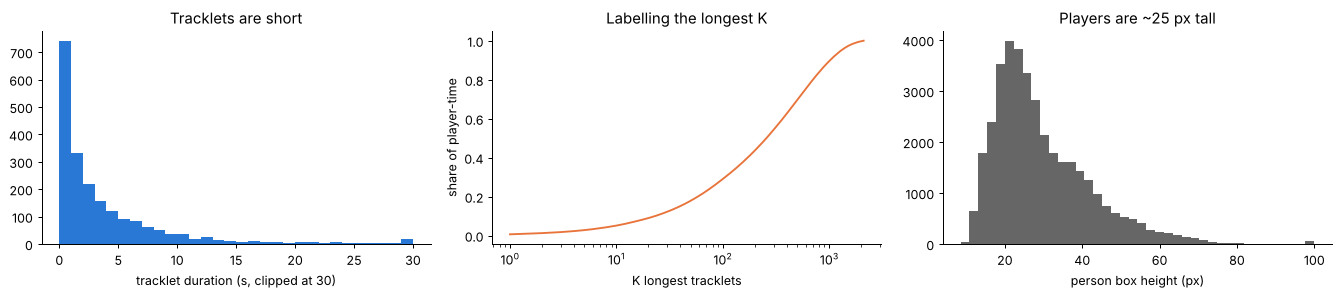

,value
segment minutes,10.0
tracklets,2102
tracklets per match (x 9),18930
median tracklet duration s,1.8
95th pct duration s,14.8
player-time covered by 30 longest,12 %
player-time covered by 200 longest,44 %
median box height px,26.2
shirt number height px (~15 % of body),3.9


In [2]:
q = tr[(tr.track_id >= 0) & (tr.cls != "outside")]
g = q.groupby("track_id").agg(t0=("t", "min"), t1=("t", "max"), n=("t", "size"), h=("y1", "median"))
g["dur"] = g.t1 - g.t0
h_box = (q.y1 - q.y0)
minutes = (q.t.max() - q.t.min()) / 60
cov = g.n.sort_values(ascending=False).cumsum() / g.n.sum()
stats = pd.Series({
    "segment minutes": round(minutes, 1),
    "tracklets": len(g), "tracklets per match (x 9)": int(len(g) * 90 / minutes),
    "median tracklet duration s": round(g.dur.median(), 1), "95th pct duration s": round(g.dur.quantile(.95), 1),
    "player-time covered by 30 longest": f"{100 * cov.iloc[29]:.0f} %",
    "player-time covered by 200 longest": f"{100 * cov.iloc[199]:.0f} %",
    "median box height px": round(h_box.median(), 1),
    "shirt number height px (~15 % of body)": round(0.15 * h_box.median(), 1)})
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].hist(g.dur.clip(upper=30), bins=30, color="#2a78d6"); ax[0].set_xlabel("tracklet duration (s, clipped at 30)"); ax[0].set_title("Tracklets are short")
ax[1].plot(np.arange(1, len(cov) + 1), cov.to_numpy(), color="#e8743b"); ax[1].set_xscale("log"); ax[1].set_xlabel("K longest tracklets"); ax[1].set_ylabel("share of player-time"); ax[1].set_title("Labelling the longest K")
ax[2].hist(h_box.clip(upper=100), bins=40, color="#666"); ax[2].set_xlabel("person box height (px)"); ax[2].set_title("Players are ~25 px tall")
plt.tight_layout()
stats.to_frame("value")

**Verdict:** labelling shirt numbers per tracklet is not feasible (≈ 19k tracklets per match, unreadable digits).
Numbers are typed only for **key events** in the review (goals, shots, cards) → `player_stats_by_number.csv`.
Automatic player identity needs higher resolution (720p+) + jersey OCR + tracklet merging (SOTA roadmap).

## 2 · Team kits: clicks vs unsupervised clustering
96 random tracklets (≥ 3 s) were labelled by eye from crops (`data/annotations/canedo_segment_team_labels.json`;
27 were too blurred / shaded to tell). Descriptors are recomputed from the video for every 5th analysed frame
(same as the perception), then the methods are compared: the stored labels (unsupervised + typed BGR kit colours),
pure unsupervised clustering, and the seeded classifier with the clicked samples of `match_setup_canedo_J2.json`.

In [ ]:
L = json.load(open(ROOT / "data/annotations/canedo_segment_team_labels.json"))["labels"]
truth = {int(k): v for k, v in L.items()}
def score(team, role=None):
    out = {}
    for c in "YGRK":
        ids = [t for t, y in truth.items() if y == c]
        if c in "YG":
            ok = [team.get(t, -1) == (0 if c == "Y" else 1) for t in ids]
            wrong = [team.get(t, -1) == (1 if c == "Y" else 0) for t in ids]
            out[f"{c} right"] = f"{sum(ok)}/{len(ids)}"; out[f"{c} other team"] = sum(wrong)
        elif c == "R":
            out["referee kept out of the teams"] = f"{sum(team.get(t, -1) == -1 for t in ids)}/{len(ids)}"
        elif role is not None:
            out["goalkeeper recognised"] = f"{sum(role.get(t) == 'goalkeeper' for t in ids)}/{len(ids)}"
    yg = [t for t, y in truth.items() if y in "YG"]
    out["outfield accuracy"] = round(float(np.mean([team.get(t, -1) == (0 if truth[t] == "Y" else 1) for t in yg])), 3)
    return out
res = {"stored run (unsupervised + typed kit colours)": score(tr.groupby("track_id").team.agg(lambda s: s.mode().iloc[0]).to_dict())}
if HAVE_VIDEO:
    fr = sorted(tr.frame.unique()); keep = set(fr[::5]); rows = []
    t0 = time.time()
    from football_eval.video import probe
    fps = probe(str(VIDEO)).fps                      # start on the run's own frame grid (stride = fps / 5)
    for f, t, img in iter_frames(str(VIDEO), 5, (tr.frame.min() + 0.01) / fps, tr.t.max() + 0.1):
        if f not in keep: continue
        g = grass_model(img)                             # pitch colour of this frame (same as the perception)
        for _, r in tr[(tr.frame == f) & (tr.track_id >= 0) & (tr.cls != "outside")].iterrows():
            c = torso_crop(img, [r.x0, r.y0, r.x1, r.y1]); d = color_descriptor(c, g) if c is not None else None
            if d is not None: rows.append((int(r.track_id), d))
    tid = np.array([r[0] for r in rows]); F = np.vstack([r[1] for r in rows])
    print(f"{len(F)} crop descriptors in {time.time() - t0:.0f}s")
    tc = TeamClassifier().fit(F); v = vote(tid, tc.predict(F))
    raw = score(v); res["unsupervised KMeans (raw cluster order)"] = raw
    res["unsupervised KMeans (order fixed by hand)"] = score({k: (1 - x if x in (0, 1) else x) for k, x in v.items()}) \
        if raw["outfield accuracy"] < 0.5 else raw
    samples = {}                                     # clicked samples re-described with the current descriptor
    for k, v_ in setup["kits"].items():
        for s_ in v_:
            im = read_frame(str(VIDEO), s_["t"]); c = torso_crop(im, s_["box"])
            d = color_descriptor(c, grass_model(im)) if c is not None else None
            if d is not None: samples.setdefault(k, []).append(d)
    kc = KitClassifier(samples).fit(F); A = vote_roles(tid, kc.predict(F)).set_index("track_id")
    res["clicked samples (6+6 outfield, 1 GK, 2 referee)"] = score(A.team.to_dict(), A.role.to_dict())
    print("seeded report:", {k: (np.round(v_, 2).tolist() if isinstance(v_, list) else v_) for k, v_ in kc.report.items()})
pd.DataFrame(res).T

**Verdict:** outfield accuracy is ~85-90 % with any method — the limit is the colour descriptor on blurred,
shaded 25-px players (SigLIP embeddings are the upgrade). What the clicks buy is **certainty**: the team identity
can never swap (unsupervised clusters can come out *swapped*), the **referee** is kept out of the teams, and
goalkeepers are recognised when their kits are clicked (only Canedo's keeper was clicked → add UD Mansores').

## 3 · Positions and pitch size: how much does a few metres move xG?

width estimates of the venue calibration ranged 52-62 m -> several metres of error near the touchlines


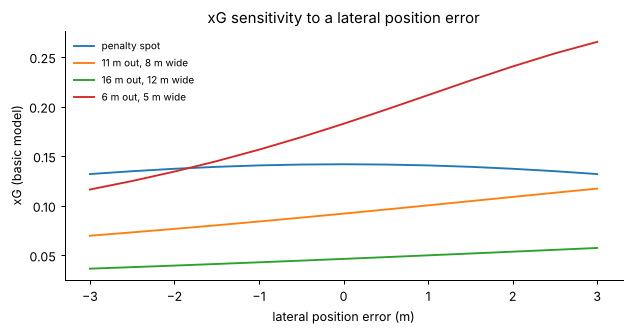

,xG,xG at -3 m,xG at +3 m,relative change
penalty spot,0.142,0.132,0.132,±7 %
"11 m out, 8 m wide",0.092,0.07,0.117,±27 %
"16 m out, 12 m wide",0.046,0.036,0.057,±24 %
"6 m out, 5 m wide",0.183,0.116,0.265,±45 %


In [4]:
from football_eval.xg import XGModel, feature_row
xgm = XGModel.load(ROOT / "models/xg_model.json")
Lp, Wp = 105.4, 61.6
spots = {"penalty spot": (Lp - 11, Wp / 2), "11 m out, 8 m wide": (Lp - 11, Wp / 2 - 8),
         "16 m out, 12 m wide": (Lp - 16, Wp / 2 - 12), "6 m out, 5 m wide": (Lp - 6, Wp / 2 - 5)}
errs = np.linspace(-3, 3, 13)
fig, ax = plt.subplots(figsize=(8, 3.6)); rows = {}
for name, (x, y) in spots.items():
    v = [xgm.predict([feature_row(x, y + d, None, Lp, Wp)], "basic")[0] for d in errs]
    ax.plot(errs, v, label=name); rows[name] = {"xG": round(v[6], 3), "xG at -3 m": round(v[0], 3), "xG at +3 m": round(v[-1], 3),
                                                 "relative change": f"±{100 * max(abs(v[0] - v[6]), abs(v[-1] - v[6])) / v[6]:.0f} %"}
ax.set_xlabel("lateral position error (m)"); ax.set_ylabel("xG (basic model)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("xG sensitivity to a lateral position error")
print("width estimates of the venue calibration ranged 52-62 m -> several metres of error near the touchlines")
pd.DataFrame(rows).T

**Verdict:** a measured pitch size is a 30-second input that removes the largest systematic position error
(the camera cannot see the far touchline well at 640 × 360). Enter it, then re-solve the camera with it fixed
(`calibrate_ptz.py --setup`).

## 4 · Direction of play and periods: how fragile is the inference?

mean x difference team0 - team1: -3.4 m on average; sign agrees with the mean in 78 % of bins
the video also holds 7.2 min of warm-up before the kick-off and 15.8 min of half-time -> the side-swap rule cannot find them


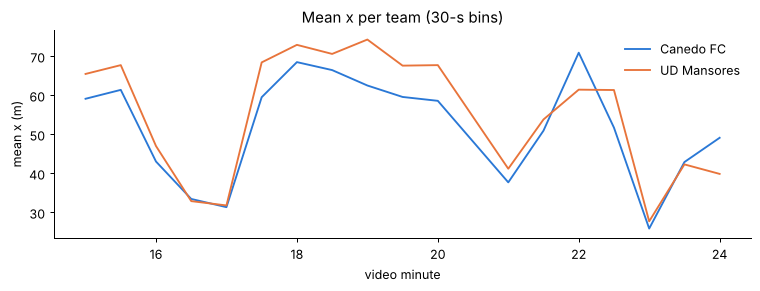

In [5]:
pp = tr[(tr.team >= 0) & tr.x.notna() & (tr.cls == "player")]
b = (pp.t // 30) * 30
m = pp.groupby([b, "team"]).x.mean().unstack()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(m.index / 60, m[0], label=setup["teams"][0]["name"], color="#2a78d6"); ax.plot(m.index / 60, m[1], label=setup["teams"][1]["name"], color="#e8743b")
ax.set_xlabel("video minute"); ax.set_ylabel("mean x (m)"); ax.legend(frameon=False); ax.set_title("Mean x per team (30-s bins)")
d = (m[0] - m[1])
print(f"mean x difference team0 - team1: {d.mean():.1f} m on average; sign agrees with the mean in {100 * (np.sign(d) == np.sign(d.mean())).mean():.0f} % of bins")
print("the video also holds", f"{setup['periods'][0]['start'] / 60:.1f} min of warm-up before the kick-off and",
      f"{(setup['periods'][1]['start'] - setup['periods'][0]['end']) / 60:.1f} min of half-time -> the side-swap rule cannot find them")

**Verdict:** the direction comes from a few metres of average position and flips every directional statistic
if wrong; the periods include long non-play stretches. Both take seconds to give → manual.

## 5 · What a 10-minute review measures (pilot)
Pilot review of the 16 sampled frames and the key event of the segment, done by Claude on 640 × 360 screenshots
(`outputs/canedo_segment/review_pilot_claude.json`). Your own review replaces it.

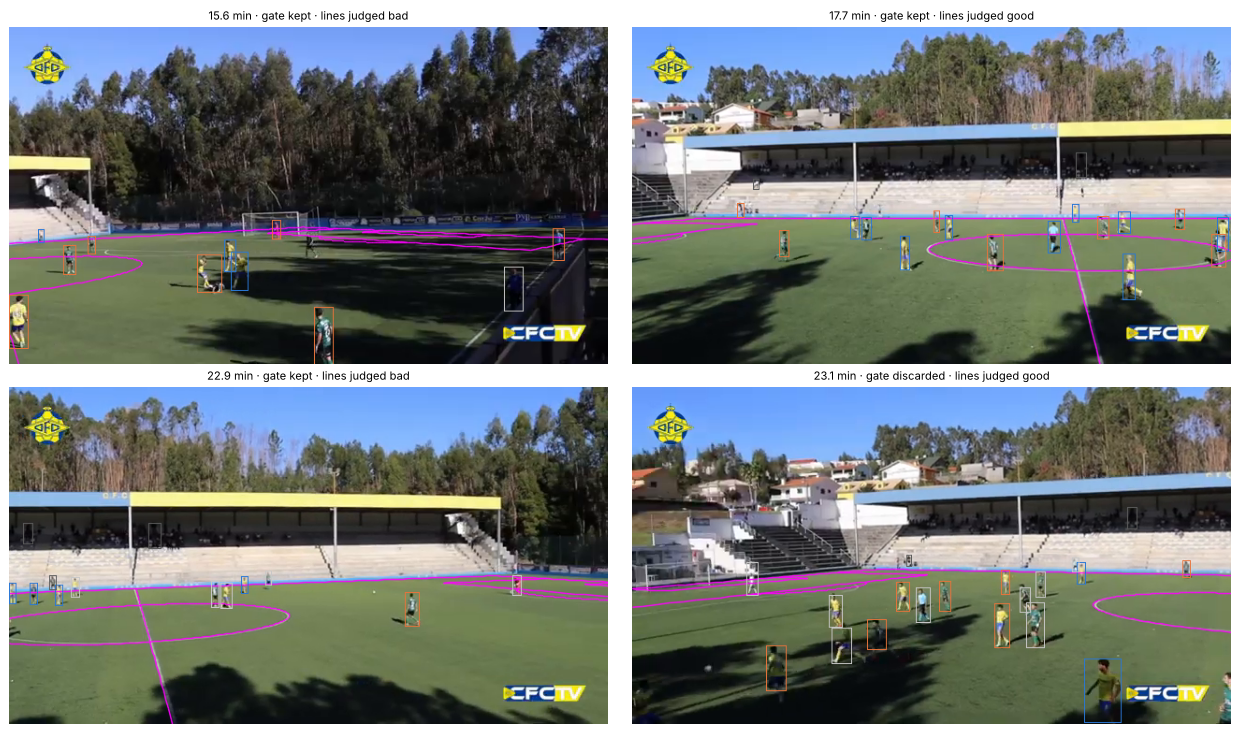

,check,result,meaning
0,pitch lines on frames used for the stats,75 % (6/8; 95 % CI 41-93 %),share of positions you can trust (camera calibration correct)
1,frames discarded by the quality gate that were actually good,33 % (1/3; 95 % CI 6-79 %),high -> the gate (pitch.ptz_max_err_px) is too strict and throws data away
2,frames without visible lines,5,cannot be judged; excluded from the share above
3,team colours correct on the frame,20 % (3/15; 95 % CI 7-45 %),frames where every visible box had the right team
4,shots that really happened,0 % (0/1; 95 % CI 0-79 %),precision of the automatic shot rule on this match


In [6]:
rv = load_review(RUN / "review_pilot_claude.json")
fc = pd.DataFrame(rv["frame_checks"])
if HAVE_VIDEO:
    cfg = load_config(ROOT / "configs/canedo_segment.yaml")
    geo = RunGeometry(str(RUN), cfg)
    pick = fc.iloc[[0, 4, 11, 12]]
    fig, axes = plt.subplots(2, 2, figsize=(14, 8.2))
    for ax, (_, c) in zip(axes.ravel(), pick.iterrows()):
        ax.imshow(geo.draw(read_frame(str(VIDEO), c.t), int(c.frame))[..., ::-1]); ax.axis("off")
        ax.set_title(f"{c.t / 60:.1f} min · gate {'kept' if c.auto_ok else 'discarded'} · lines judged {c.lines}", fontsize=9)
    plt.tight_layout()
validation_summary(rv)

**Verdict:** the automatic camera-quality gate is useful but not sufficient (wrong poses pass it, good ones
are thrown away), and the only "shot" in the segment did not happen. Both are invisible without a look — a short
review turns them into measured numbers in the report and fixes the events that matter.

## 6 · The Canedo setup file: what is still to do

In [7]:
pd.DataFrame(checklist(setup, ROOT))[["item", "status", "detail", "impact"]]

,item,status,detail,impact
0,video,ok,data/videos/2026-10-18_UD_Mansores_vs_Canedo_FC_J2.mp4,everything
1,pitch size,warn,105.4 x 61.6 m estimated by the camera calibration,width estimates varied 52-62 m on the Canedo video — enter the real size
2,overlays,warn,2 region(s) (confirmed),"pre-filled, not yet confirmed by you — check it in the setup UI (crest + CFC TV logo (from configs/canedo_cfctv.yaml))"
3,periods,warn,"7:10-55:15, 71:02-122:50","pre-filled, not yet confirmed by you — check it in the setup UI (kick-offs 7:10 / 71:02, ends ~55:15 / ~122:50 read by eye in an earlier session)"
4,attacking direction,warn,Canedo FC attacks right in the 1st half,"pre-filled, not yet confirmed by you — check it in the setup UI (inferred: yellow (Canedo) lines up in the left half at the 7:10 kick-off and averages the lower x over minutes 15-25)"
5,team names,warn,Canedo FC vs UD Mansores,"pre-filled, not yet confirmed by you — check it in the setup UI (names from configs/canedo_cfctv.yaml)"
6,kits: outfield,warn,6 + 6 samples,"pre-filled, not yet confirmed by you — check it in the setup UI (clicked by Claude on 7 frames (sun + shade, both halves); the pink/red goalkeeper at the left goal at 43:20 assumed Canedo (defends left in the 1st half); no UD Mansores goalkeeper sample yet)"
7,kits: goalkeepers,warn,1 + 0 samples,"goalkeepers otherwise guessed from time spent in the box (xG freeze frame, saves)"
8,kits: referee,warn,2 samples,"pre-filled, not yet confirmed by you — check it in the setup UI (clicked by Claude on 7 frames (sun + shade, both halves); the pink/red goalkeeper at the left goal at 43:20 assumed Canedo (defends left in the 1st half); no UD Mansores goalkeeper sample yet)"
9,calibration,warn,"venue camera configs/camera_canedo_ptz.json; 4 landmark frame(s), 9 points","pre-filled, not yet confirmed by you — check it in the setup UI (landmarks from configs/landmarks_canedo.json + solved venue camera)"


Sections pre-filled by Claude are shown as *warn* until you confirm them in
`python scripts/match_ui.py setup --video data/videos/2026-10-18_UD_Mansores_vs_Canedo_FC_J2.mp4 --setup configs/match_setup_canedo_J2.json --config configs/canedo_cfctv.yaml`.
Still missing: the real pitch size, UD Mansores' goalkeeper kit, the final score and goal minutes.